
# Capítulo 4: Transformada de Fourier de Señales periódicas y aperiódicas

📖 `Libro: Análisis de Señales Utilizando Python`

**Autor: Dora María Ballesteros Larrotta**  
Universidad Militar Nueva Granada (UMNG)

---

## Material complementario del libro

Este notebook acompaña el **Capítulo 4** y contiene un ejemplo de espectro de señal periódica:  Suma de Señales Cosenoidales.



### 📊 Ejercicio. Representación de una señal periódica en el dominio del tiempo y de la frecuencia

Se considera la siguiente señal periódica, compuesta por tres componentes sinusoidales:

$$
x(t)=16\cos(2\cdot 2\pi f_0t)+10\cos(3\cdot 2\pi f_0t)+20\cos(5\cdot 2\pi f_0t)
$$

A partir de esta señal, se realizarán las siguientes representaciones:

1. 🔵 **Dominio del tiempo:** gráfica de $x(t)$.
2. 🟣 **Coeficientes de la Serie de Fourier (SF):** representación de los coeficientes complejos $C_k$ en función del índice armónico $k$.
3. 🟢 **Espectro $X(jf)$:** representación de la señal en el dominio de la frecuencia $f$, expresada en Hz.
4. 🟠 **Espectro $X(j\omega)$:** representación de la señal en el dominio de la frecuencia angular $\omega$, expresada en rad/s.

**Objetivo:** Analizar la relación entre los coeficientes de la Serie de Fourier y la representación espectral de una señal periódica, identificando las frecuencias y amplitudes de sus componentes armónicas.


# **1. Señal en el dominio del tiempo**

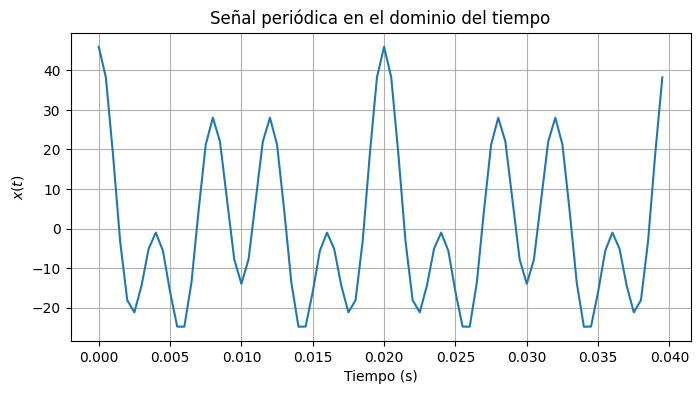

In [37]:

import numpy as np
import matplotlib.pyplot as plt

# Parámetros de la señal
fo = 50  # frecuencia fundamental de la señal [Hz]
fs = 40 * fo  # frecuencia de muestreo (cumple Nyquist)
ciclos = 2  # cantidad de ciclos a visualizar
stop = ciclos / fo  # tiempo final
ns = int(stop * fs)  # número de muestras

# Vector de tiempo (alineado exactamente con la fs)
t = np.arange(0, stop, 1/fs)

# Definición de la señal
x = 16*np.cos(2*2*np.pi*fo*t) + 10*np.cos(3*2*np.pi*fo*t) + 20*np.cos(5*2*np.pi*fo*t)

# Configuración de la figura
plt.rcParams["figure.figsize"] = (8,4)

# Gráfica
plt.plot(t, x)

plt.title('Señal periódica en el dominio del tiempo')
plt.xlabel('Tiempo (s)')
plt.ylabel('$x(t)$')

plt.grid(True)
plt.show()


# **2. Coeficientes de la Serie de Fourier (SF)**

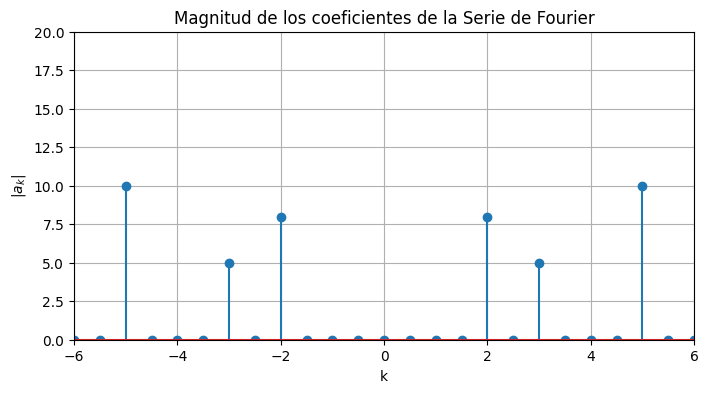

In [38]:
from scipy.fft import fft, fftfreq
import numpy as np
import matplotlib.pyplot as plt

# número de muestras
n = len(x)

# Serie de Fourier
ak = fft(x) / n
k = fftfreq(n, 1/fs)

# posiciones armónicas
k = k / fo

# Configurar la visualización
plt.stem(k, np.abs(ak))
plt.xlim(-6, 6)
plt.ylim(0, 20)

plt.xlabel('k')
plt.ylabel(r'$|a_k|$')
plt.title('Magnitud de los coeficientes de la Serie de Fourier')

plt.grid(True)
plt.show()

# **3.  Espectro X(jf)**


📊 **Transformada de Fourier de una señal periódica: $X(jf)$**

La Transformada de Fourier de una señal periódica se obtiene a partir de los coeficientes de su Serie de Fourier ($a_k$), mediante:

$$
\boxed{
X(jf)=\sum_{k=-\infty}^{\infty}a_k\,\delta(f-kf_0)
}
$$

Donde:

- $a_k$: coeficientes complejos de la Serie de Fourier.
- $f_0$: frecuencia fundamental de la señal, expresada en Hz.
- $k$: índice armónico, con $k\in\mathbb{Z}$.
- $\delta(f-kf_0)$: impulso de Dirac ubicado en la frecuencia $f=kf_0$.

**Interpretación:** El espectro de una señal periódica está formado por impulsos de Dirac ubicados en los múltiplos enteros de la frecuencia fundamental, cuyos pesos corresponden a los coeficientes $a_k$.


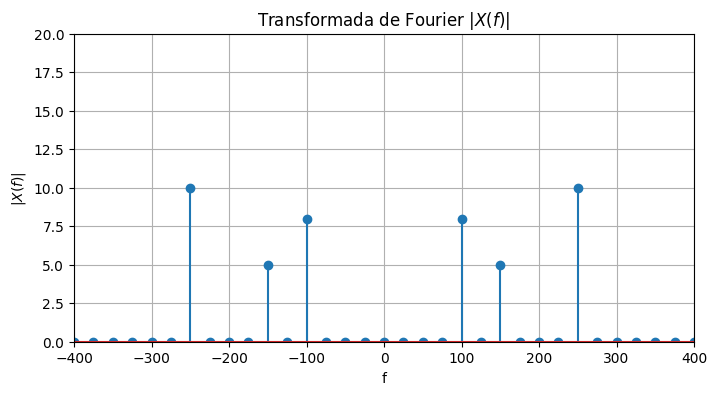

In [44]:
from scipy.fft import fft, fftfreq
import numpy as np
import matplotlib.pyplot as plt

# número de muestras
n = len(x)

# Transformada de Fourier
X_f = fft(x) / n
f = fftfreq(n, 1/fs)

# Configurar la visualización
plt.stem(f, np.abs(X_f))
plt.xlim(-400, 400)
plt.ylim(0, 20)

plt.xlabel('f')
plt.ylabel(r'$|X(f)|$')
plt.title('Transformada de Fourier $|X(f)|$')

plt.grid(True)
plt.show()

# **4.  Espectro X(jw)**


📊 **Transformada de Fourier de una señal periódica: $X(j\omega)$**

La Transformada de Fourier de una señal periódica, expresada en función de la frecuencia angular $\omega$, se obtiene a partir de los coeficientes de su Serie de Fourier ($a_k$), mediante:

$$
\boxed{
X(j\omega)=2\pi\sum_{k=-\infty}^{\infty}a_k\,\delta(\omega-k\omega_0)
}
$$

Donde:

- $a_k$: coeficientes complejos de la Serie de Fourier.
- $\omega_0=2\pi f_0$: frecuencia angular fundamental, expresada en rad/s.
- $k$: índice armónico, con $k\in\mathbb{Z}$.
- $\delta(\omega-k\omega_0)$: impulso de Dirac ubicado en la frecuencia angular $\omega=k\omega_0$.

**Interpretación:** El espectro de una señal periódica está formado por impulsos de Dirac ubicados en los múltiplos enteros de la frecuencia angular fundamental, cuyos pesos corresponden a $2\pi a_k$.

**Comparación con $X(jf)$:** Al expresar la Transformada de Fourier en función de $\omega$, las posiciones de los impulsos se multiplican por $2\pi$, al igual que sus pesos.


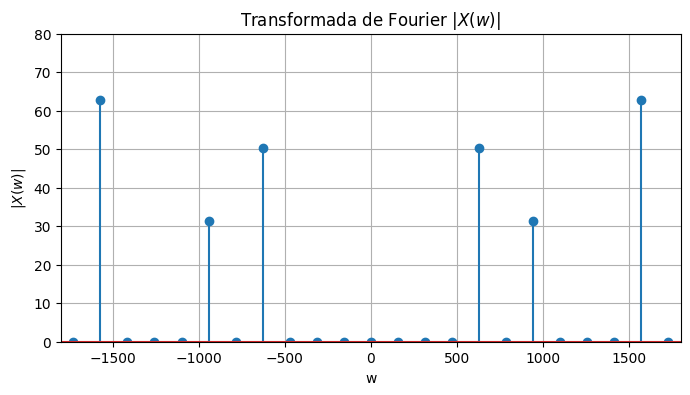

In [48]:
from scipy.fft import fft, fftfreq
import numpy as np
import matplotlib.pyplot as plt

# número de muestras
n = len(x)

# Transformada de Fourier
X_w = 2*np.pi * fft(x) / n
w = 2 * np.pi*fftfreq(n, 1/fs)

# Configurar la visualización
plt.stem(w, np.abs(X_w))
plt.xlim(-1800, 1800)
plt.ylim(0, 80)

plt.xlabel('w')
plt.ylabel(r'$|X(w)|$')
plt.title('Transformada de Fourier $|X(w)|$')

plt.grid(True)
plt.show()